In [1]:
import numpy as np
import sys
sys.path.append('/home/samanwaya.mukherjee/gwfit/gwfit')
sys.path.append('/home/samanwaya/gwfit/gwfit')
import imrphenomd_horizon as phenom_wf
import useful_relations as urel
import matplotlib.pyplot as plt
import waveform_functions as wfn

from pycbc.waveform import get_fd_waveform
from pycbc.filter import match
from pycbc.psd import aLIGOZeroDetHighPower

import time as tt

/home/samanwaya.mukherjee/.conda/envs/lalsuite-esigma/lib/python3.10/site-packages/matplotlib/cbook/__init__.py:1298: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


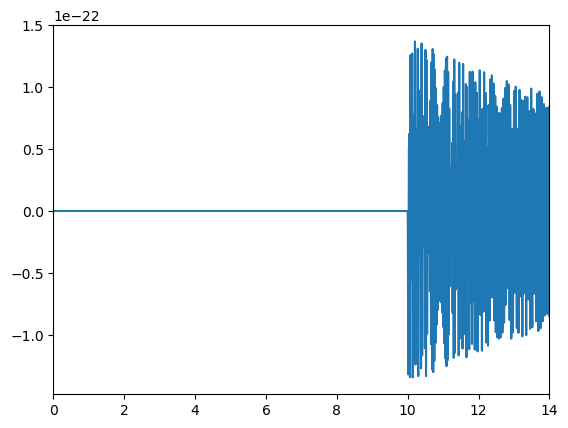

time taken to generate PhenomD_Horizon = 3.090 secs
time taken to generate PhenomD = 0.026 secs


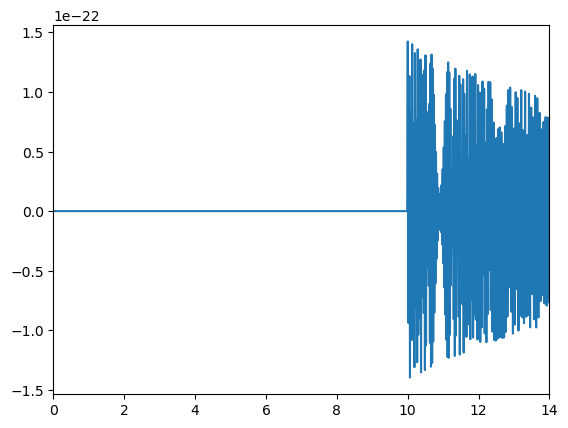

The mismatch is: 0.85%


In [2]:
Ms=30
q=7
m1=Ms*q/(1+q)
m2=Ms/(1+q)
chi1=-0.8
chi2=-0.8
f_low=10
delta_f=2**-6
# %matplotlib notebook

start1=tt.time()
hp, hc = phenom_wf.get_imrphenomd_horizon_fd(m1=m1,m2=m2,chi1=chi1,chi2=chi2,f_lower=f_low,delta_f=delta_f,phase_corr=1,amp_corr=1)
end1=tt.time()

time1=end1-start1

plt.plot(hp.sample_frequencies,hp)
plt.xlim(0,f_low+4)
plt.show()

start2=tt.time()
sp, sc = get_fd_waveform(approximant="IMRPhenomD",
                         mass1=m1,
                         mass2=m2,
                         spin1z=chi1,
                         spin2z=chi2,
                         f_lower=f_low,
                         distance=200,
                         delta_f=delta_f)
end2=tt.time()
time2=end2-start2
print(f'time taken to generate PhenomD_Horizon = {time1:.3f} secs')
print(f'time taken to generate PhenomD = {time2:.3f} secs')

plt.plot(sp.sample_frequencies,sp)
plt.xlim(0,f_low+4)
plt.show()

# Resize the waveforms to the same length
tlen = max(len(sp), len(hp))
sp.resize(tlen)
hp.resize(tlen)

# # Generate the aLIGO ZDHP PSD
# delta_f = 1.0 / sp.duration
# flen = tlen//2 + 1
psd = aLIGOZeroDetHighPower(len(sp), delta_f, f_low)

# Note: This takes a while the first time as an FFT plan is generated
# subsequent calls are much faster.
m, i = match(hp, sp, psd=psd, low_frequency_cutoff=f_low)
print(f'The mismatch is: {(1-m)*100:.2f}%')

time taken to generate PhenomD_Horizon = 5.137 secs
time taken to generate PhenomD = 5.120 secs
---------------------------------------------------------
q: 1.00, The mismatch is: 56.47%
---------------------------------------------------------
time taken to generate PhenomD_Horizon = 5.170 secs
time taken to generate PhenomD = 5.165 secs
---------------------------------------------------------
q: 2.00, The mismatch is: 58.08%
---------------------------------------------------------
time taken to generate PhenomD_Horizon = 5.193 secs
time taken to generate PhenomD = 5.383 secs
---------------------------------------------------------
q: 3.00, The mismatch is: 59.25%
---------------------------------------------------------
time taken to generate PhenomD_Horizon = 5.278 secs
time taken to generate PhenomD = 5.258 secs
---------------------------------------------------------
q: 4.00, The mismatch is: 56.84%
---------------------------------------------------------
time taken to genera

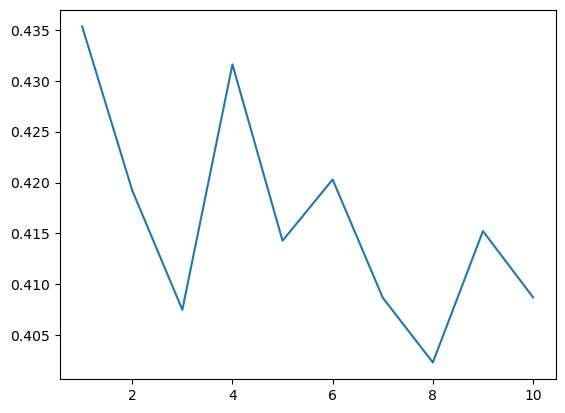

In [4]:
Ms=50
M=Ms*urel.MTsun
q_arr = np.linspace(1,10,10)
match1 = []
for q in q_arr:    
    m1=Ms*q/(1+q)
    m2=Ms/(1+q)
    chi1=0
    chi2=0
    f_low=0.01/M
    delta_f=2**-6
    # %matplotlib notebook
    
    start1=tt.time()
    hp, hc = phenom_wf.get_imrphenomd_heated_fd(m1=m1,m2=m2,chi1=chi1,chi2=chi2,f_lower=f_low,delta_f=delta_f,phase_corr=1,amp_corr=1,H=1)
    end1=tt.time()
    
    time1=end1-start1

    start2=tt.time()
    sp, sc = phenom_wf.get_imrphenomd_heated_fd(m1=m1,m2=m2,chi1=chi1,chi2=chi2,f_lower=f_low,delta_f=delta_f,phase_corr=1,amp_corr=1,H=0)
    end2=tt.time()
    
    time2=end2-start2
    
    # plt.plot(hp.sample_frequencies,hp)
    # plt.xlim(0,f_low+4)
    # plt.show()
    
    # start2=tt.time()
    # sp, sc = get_fd_waveform(approximant="IMRPhenomD",
    #                          mass1=m1,
    #                          mass2=m2,
    #                          spin1z=chi1,
    #                          spin2z=chi2,
    #                          f_lower=f_low,
    #                          distance=200,
    #                          delta_f=delta_f)
    # end2=tt.time()
    # time2=end2-start2
    print(f'time taken to generate PhenomD_Horizon = {time1:.3f} secs')
    print(f'time taken to generate PhenomD = {time2:.3f} secs')
    
    # plt.plot(sp.sample_frequencies,sp)
    # plt.xlim(0,f_low+4)
    # plt.show()
    
    # Resize the waveforms to the same length
    tlen = max(len(sp), len(hp))
    sp.resize(tlen)
    hp.resize(tlen)
    
    # # Generate the aLIGO ZDHP PSD
    # delta_f = 1.0 / sp.duration
    # flen = tlen//2 + 1
    psd = aLIGOZeroDetHighPower(len(sp), delta_f, f_low)
    
    # Note: This takes a while the first time as an FFT plan is generated
    # subsequent calls are much faster.
    m1, i = match(hp, sp, psd=psd, low_frequency_cutoff=0.03/M)
    print('---------------------------------------------------------')
    print(f'q: {q:.2f}, The mismatch is: {(1-m1)*100:.2f}%')
    print('---------------------------------------------------------')
    match1.append(m1)

plt.plot(q_arr,match1)
plt.show()

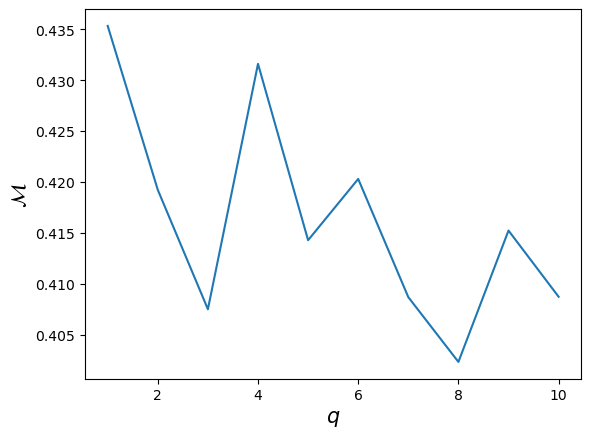

In [5]:
plt.plot(q_arr,match1)
plt.xlabel('$q$',fontsize=15)
plt.ylabel('$\\mathcal{M}$',fontsize=15)
plt.show()

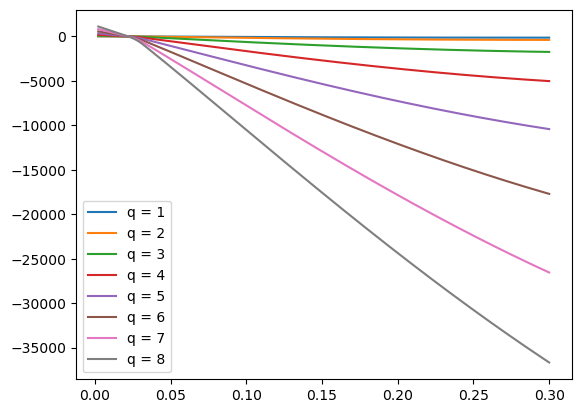

In [3]:
import useful_relations as urel
import nr_heat
Ms=30
M=Ms*urel.MTsun
q_arr = np.linspace(1,8,8)
for q in q_arr:    
    m1=Ms*q/(1+q)
    m2=Ms/(1+q)
    chi1=0
    chi2=0
    f_low=15
    f_high=0.3/M
    delta_f=2**-6
    f=np.arange(f_low,f_high,delta_f)
    imr_phase_TH = nr_heat.imr_tidal_heating_approximant(f,m1,m2)
    # plt.plot(M*f,abs(imr_phase_TH),label=f'q = {int(q)}')
    plt.plot(M*f,imr_phase_TH,label=f'q = {int(q)}')
    # plt.yscale('log')
plt.legend()
plt.show()

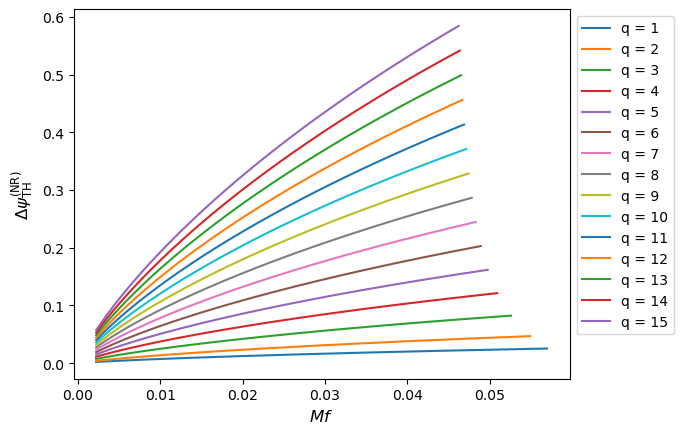

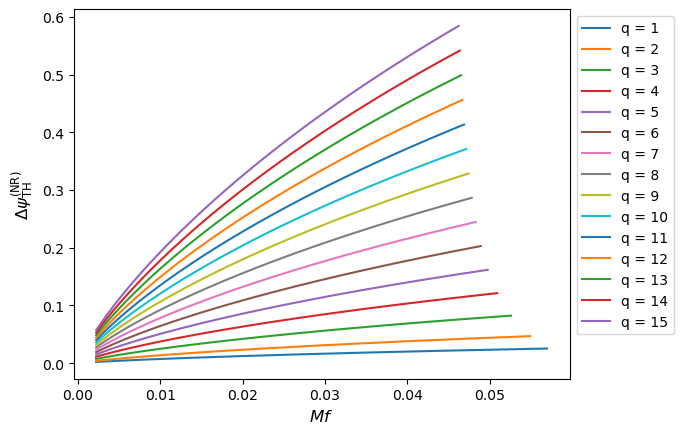

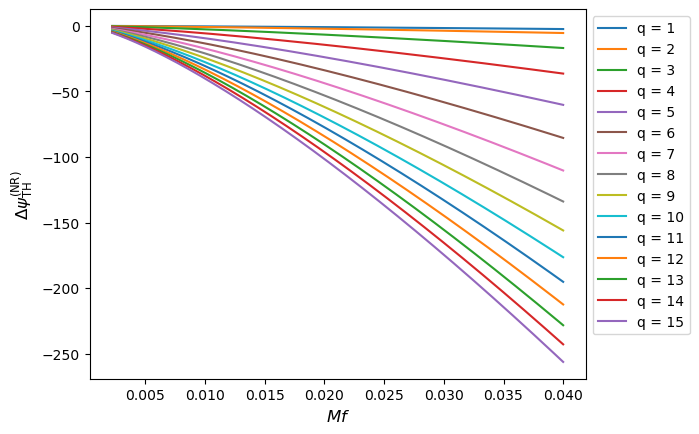

In [18]:
import useful_relations as urel
import inspiral_model as insp
import nr_heat
Ms=30
M=Ms*urel.MTsun
q_arr = np.linspace(1,15,15)
for q in q_arr:    
    m1=Ms*q/(1+q)
    m2=Ms/(1+q)
    chi1=0
    chi2=0
    f_low=15
    f_high=wfn.Mf_peak_td_fit(m1,m2)/M
    delta_f=2**-6
    f=np.arange(f_low,f_high,delta_f)
    # imr_phase_TH = nr_heat.psiTH_from_nr(f,m1,m2)
    # imr_phase_TH = insp.psiTH_new(f,m1,m2,0,0)
    imr_phase_TH = insp.psiTH(f,m1,m2,0,0,1,1)
    plt.plot(M*f,imr_phase_TH,label=f'q = {int(q)}')
# plt.yscale('log')
# plt.xscale('log')
plt.xlabel('$Mf$',fontsize=12)
plt.ylabel('$\\Delta\psi_{\\rm TH}^{(\\rm NR)}$',fontsize=12)
plt.legend(bbox_to_anchor=(1, 1))
# plt.savefig('/home/samanwaya/gwfit/Plots/NR_phase.jpg')
plt.show()

for q in q_arr:    
    m1=Ms*q/(1+q)
    m2=Ms/(1+q)
    chi1=0
    chi2=0
    f_low=15
    f_high=wfn.Mf_peak_td_fit(m1,m2)/M
    delta_f=2**-6
    f=np.arange(f_low,f_high,delta_f)
    # imr_phase_TH = nr_heat.psiTH_from_nr(f,m1,m2)
    imr_phase_TH = insp.psiTH_new(f,m1,m2,0,0)
    # imr_phase_TH = insp.psiTH(f,m1,m2,0,0,1,1)
    plt.plot(M*f,imr_phase_TH,label=f'q = {int(q)}')
# plt.yscale('log')
# plt.xscale('log')
plt.xlabel('$Mf$',fontsize=12)
plt.ylabel('$\\Delta\psi_{\\rm TH}^{(\\rm NR)}$',fontsize=12)
plt.legend(bbox_to_anchor=(1, 1))
# plt.savefig('/home/samanwaya/gwfit/Plots/NR_phase.jpg')
plt.show()

for q in q_arr:    
    m1=Ms*q/(1+q)
    m2=Ms/(1+q)
    chi1=0
    chi2=0
    f_low=15
    f_high= 0.04/M #wfn.Mf_peak_td_fit(m1,m2)/M
    delta_f=2**-6
    f=np.arange(f_low,f_high,delta_f)
    imr_phase_TH = nr_heat.psiTH_from_nr(f,m1,m2,PN_order=4.5)
    imr_phase_TH2 = insp.psiTH_new(f,m1,m2,0,0)
    plt.plot(M*f,imr_phase_TH,label=f'q = {int(q)}')
    # plt.plot(M*f,imr_phase_TH2,c='grey',alpha=0.7)
# plt.yscale('log')
# plt.xscale('log')
plt.xlabel('$Mf$',fontsize=12)
plt.ylabel('$\\Delta\psi_{\\rm TH}^{(\\rm NR)}$',fontsize=12)
plt.legend(bbox_to_anchor=(1, 1))
# plt.savefig('/home/samanwaya/gwfit/Plots/NR_phase.jpg')
plt.show()

In [ ]:
from pycbc.waveform import get_td_waveform
from pycbc.filter import match
from pycbc.psd import aLIGOZeroDetHighPower

f_low = 10
delta_f=2**-5
# Generate the two waveforms to compare
hp, hc = get_fd_waveform(approximant="IMRPhenomD",
                         mass1=2.,
                         mass2=2.,
                         f_lower=f_low,
                         delta_f=delta_f)

sp, sc = get_fd_waveform(approximant="IMRPhenomD_NRTidal",
                         mass1=2.,
                         mass2=2.,
                         f_lower=f_low,
                         lambda1=800,
                         lambda2=800,
                         delta_f=delta_f)

# Resize the waveforms to the same length
flen = max(len(sp), len(hp))
sp.resize(flen)
hp.resize(flen)

psd = aLIGOZeroDetHighPower(flen, delta_f, f_low)

# Note: This takes a while the first time as an FFT plan is generated
# subsequent calls are much faster.
m, i = match(hp, sp, psd=psd, low_frequency_cutoff=f_low)
print(f'The mismatch is: {(1-m)*100:.4f}%')



141.52876274210044


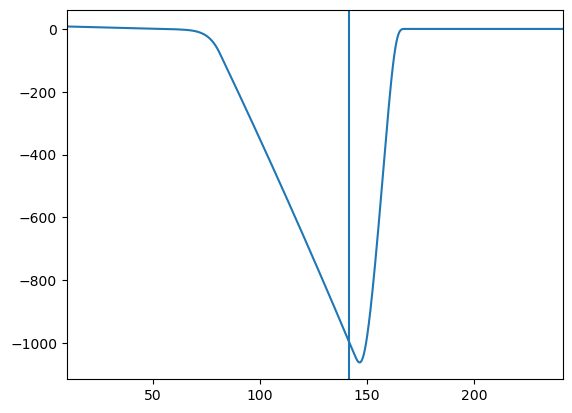

In [14]:
import nr_heat
import waveform_functions as wfn
m1=30
m2=50
f=np.arange(10,3000,0.1)
M = (m1+m2)*urel.MTsun

imr_phase_TH = nr_heat.imr_tidal_heating_approximant(f,m1,m2)
merger_f = wfn.Mf_peak_td_fit(m1,m2)/M
print(merger_f)
imr_phase_TH = imr_phase_TH*urel.planck_taper_window(f,t3=merger_f,t4=merger_f*1.2,only_right=True)

plt.plot(f,imr_phase_TH)
plt.xlim(10,merger_f+100)
plt.axvline(merger_f)
plt.show()

[ 1321.45997596 -5912.82846972  6618.37273801    -7.89189329]


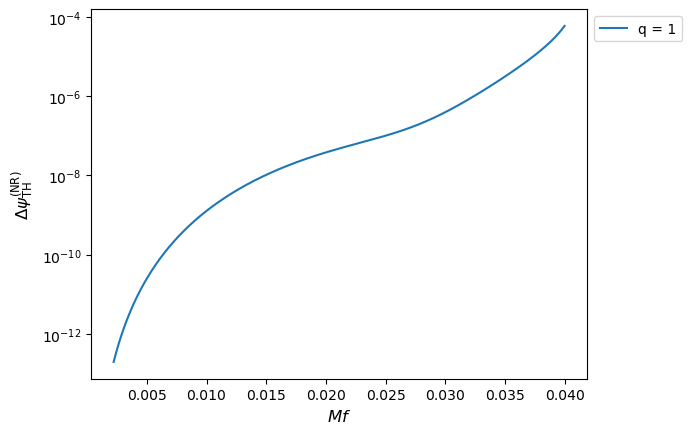

In [20]:
def fit_parameters_from_nr_all(m1,m2):
	
	beta = [
				[37477.34749966299, -289247.10018962296, 578494.2003792459],
				[-162359.6987223983, 1251574.962021433, -2503149.924042866],
				[176200.9487269253, -1356660.6079112913, 2713321.2158225826],
				[-40.91612892292342, 264.19388508910976, -528.3877701782195]
			]

	eta = m1*m2/(m1+m2)**2
	a = np.zeros(4)
	for i in range(4):
		for j in range(3):
			a[i] += beta[i][j]*eta**j

	return a

def dmdt_from_nr(f,m1,m2):
	
    eta = m1*m2/(m1+m2)**2
    Mf = (m1+m2)*urel.MTsun*f
    v = (np.pi*Mf)**(1./3.)
    
    a = fit_parameters_from_nr_all(m1,m2)
    a1 = a[0]
    a2 = a[1]
    a3 = a[2]
    b1 = a[3]

    x1=m1/(m1+m2)
    x2=m2/(m1+m2)
    A = (32./5.)*(x1**4 + x2**4)

    dmdt = A*eta**2*v**18*(1+eta*(a1*v+a2*v**2+a3*v**3))/(1+eta*b1*v)

    return dmdt


Ms=30
M=Ms*urel.MTsun
q_arr = [1]
for q in q_arr:    
    m1=Ms*q/(1+q)
    m2=Ms/(1+q)
    print(fit_parameters_from_nr_all(m1,m2))
    chi1=0
    chi2=0
    f_low=15
    f_high=0.04/M #wfn.Mf_peak_td_fit(m1,m2)/M
    delta_f=2**-6
    f=np.arange(f_low,f_high,delta_f)
    dmdt = dmdt_from_nr(f,m1,m2)
    plt.plot(M*f,dmdt,label=f'q = {int(q)}')
plt.yscale('log')
# plt.xscale('log')
plt.xlabel('$Mf$',fontsize=12)
plt.ylabel('$\\Delta\psi_{\\rm TH}^{(\\rm NR)}$',fontsize=12)
plt.legend(bbox_to_anchor=(1, 1))
# plt.savefig('/home/samanwaya/gwfit/Plots/NR_phase.jpg')
plt.show()